In [41]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
bs_dir = "./archive (3)"
splits = ['train', 'valid', 'test']
classes = ['autistic', 'non_autistic']

split_cnt = []
for split in splits:
    for label in classes:
        folder_path = os.path.join(bs_dir, split, label)
        n_images = len(os.listdir(folder_path))
        split_cnt.append({'Split': split, 'Label': label, 'Count': n_images})

In [43]:
df_splits = pd.DataFrame(split_cnt)
print(df_splits)

   Split         Label  Count
0  train      autistic   1263
1  train  non_autistic   1263
2  valid      autistic    100
3  valid  non_autistic    100
4   test      autistic    100
5   test  non_autistic    100


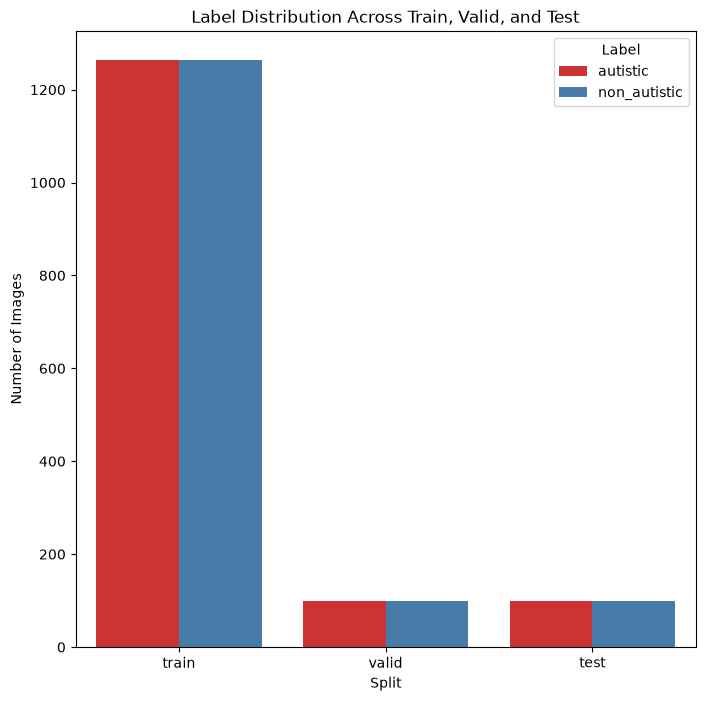

In [44]:
plt.figure(figsize = (8, 8))
sns.barplot(data = df_splits, x = 'Split', y = 'Count', hue = 'Label', palette = 'Set1')
plt.title('Label Distribution Across Train, Valid, and Test')
plt.ylabel('Number of Images')
plt.show()

In [45]:
train_dir = os.path.join(bs_dir, 'train')
train_info = []

In [46]:
for label in classes:
    folder_path = os.path.join(train_dir, label)
    images = os.listdir(folder_path)
    for img_name in images:
        img_path = os.path.join(folder_path, img_name)
        train_info.append({'filepath': img_path, 'label': label})

df_train = pd.DataFrame(train_info)

A Random Sample from the Dataset


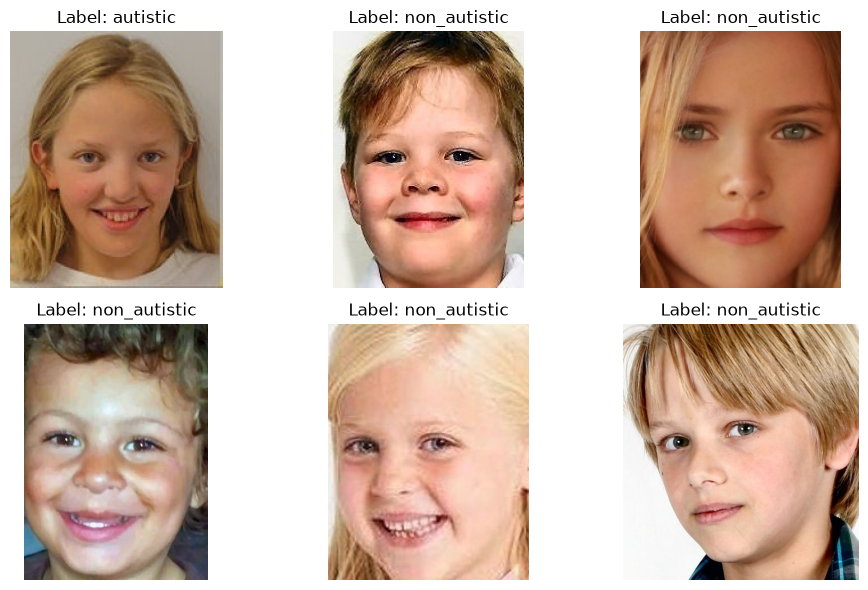

In [47]:
print("A Random Sample from the Dataset")
def sample_imgs(dataframe, num_images = 6):
    sample_df = dataframe.sample(num_images)
    plt.figure(figsize = (10, 6))
    for i, (index, row) in enumerate(sample_df.iterrows()):
        imgs = cv2.imread(row['filepath'])
        imgs = cv2.cvtColor(imgs, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 3, i + 1)
        plt.imshow(imgs)
        plt.title(f"Label: {row['label']}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

sample_imgs(df_train)

The Dimensions of the Training Images


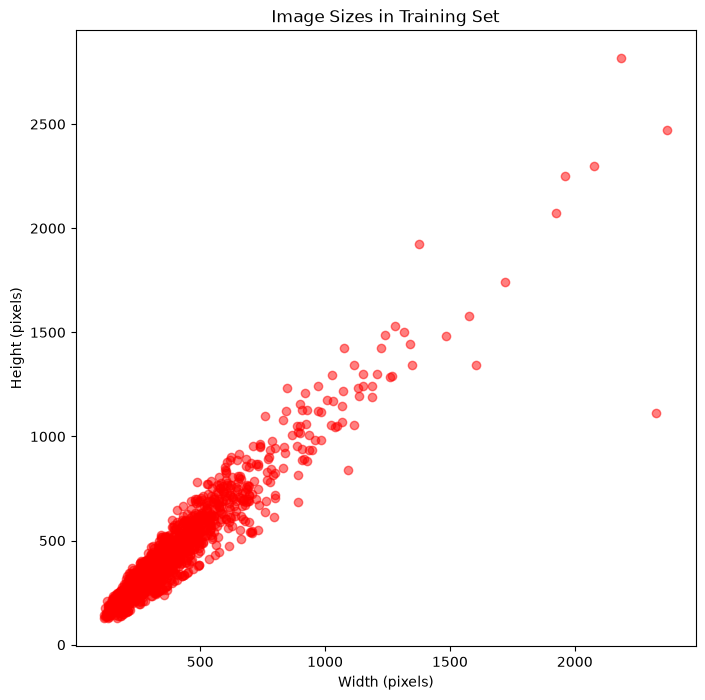

In [48]:
print("The Dimensions of the Training Images")
w, h = [], []
for path in df_train['filepath']:
    img = cv2.imread(path)
    height, width, _ = img.shape
    w.append(width)
    h.append(height)

plt.figure(figsize = (8, 8))
plt.scatter(w, h, alpha = 0.5, color = 'red')
plt.title('Image Sizes in Training Set')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.show()

In [49]:
print(f"Average Width: {np.mean(w):.0f} pixels")
print(f"Average Height: {np.mean(h):.0f} pixels")

Average Width: 322 pixels
Average Height: 369 pixels


In [50]:
import cv2
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)

def preprocess_image(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    img = preprocess_input(img)
    return img

In [51]:
X = []
y = []

label_map = {
    'autistic': 1,
    'non_autistic': 0
}

for _, row in df_train.iterrows():
    img = preprocess_image(row['filepath'])
    X.append(img)
    y.append(label_map[row['label']])

X = np.array(X)
y = np.array(y)

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [53]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

cnn_model = Sequential()

cnn_model.add(Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)))
cnn_model.add(MaxPooling2D(2,2))

cnn_model.add(Conv2D(64, (3,3), activation='relu'))
cnn_model.add(MaxPooling2D(2,2))

cnn_model.add(Conv2D(128, (3,3), activation='relu'))
cnn_model.add(MaxPooling2D(2,2))

cnn_model.add(Flatten())
cnn_model.add(Dense(128, activation='relu'))
cnn_model.add(Dropout(0.5))
cnn_model.add(Dense(1, activation='sigmoid'))

c:\Users\moazm\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [54]:
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [55]:
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 35s 448ms/step - accuracy: 0.6213 - loss: 0.7367 - val_accuracy: 0.7332 - val_loss: 0.6069
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 27s 426ms/step - accuracy: 0.7010 - loss: 0.5719 - val_accuracy: 0.7372 - val_loss: 0.5501
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 28s 442ms/step - accuracy: 0.7371 - loss: 0.5380 - val_accuracy: 0.7490 - val_loss: 0.4974
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 26s 405ms/step - accuracy: 0.7574 - loss: 0.4989 - val_accuracy: 0.7589 - val_loss: 0.5022
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 26s 406ms/step - accuracy: 0.7941 - loss: 0.4378 - val_accuracy: 0.7628 - val_loss: 0.5045
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 27s 414ms/step - accuracy: 0.8094 - loss: 0.3984 - val_accuracy: 0.7826 - val_loss: 0.4837
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 26s 404ms/step - accuracy: 0.8604 - loss: 0.3286 - val_accuracy: 0.7866 - val_loss: 0.4823
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 25s 396ms/step - accuracy: 0.8802 - loss: 0.2774 - val_accu

In [56]:
loss, acc = cnn_model.evaluate(X_val, y_val)
print("CNN Accuracy:", acc)

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.7628 - loss: 0.6877
CNN Accuracy: 0.7628458738327026


In [57]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(1, activation='sigmoid')(x)

mobilenet_model = Model(inputs=base_model.input, outputs=output)

In [58]:
mobilenet_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [59]:
history2 = mobilenet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 34s 472ms/step - accuracy: 0.6891 - loss: 0.6007 - val_accuracy: 0.7451 - val_loss: 0.4851
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 28s 445ms/step - accuracy: 0.7505 - loss: 0.5009 - val_accuracy: 0.7648 - val_loss: 0.4621
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 28s 434ms/step - accuracy: 0.7985 - loss: 0.4444 - val_accuracy: 0.7688 - val_loss: 0.4506
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 29s 449ms/step - accuracy: 0.8119 - loss: 0.4218 - val_accuracy: 0.7767 - val_loss: 0.4602
Epoch 5/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 27s 426ms/step - accuracy: 0.8178 - loss: 0.3991 - val_accuracy: 0.7727 - val_loss: 0.4384


In [60]:
loss2, acc2 = mobilenet_model.evaluate(X_val, y_val)
print("MobileNetV2 Accuracy:", acc2)

16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 363ms/step - accuracy: 0.7727 - loss: 0.4384
MobileNetV2 Accuracy: 0.7727272510528564


In [61]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = mobilenet_model.predict(X_val)
y_pred = (y_pred > 0.5).astype(int)

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 423ms/step


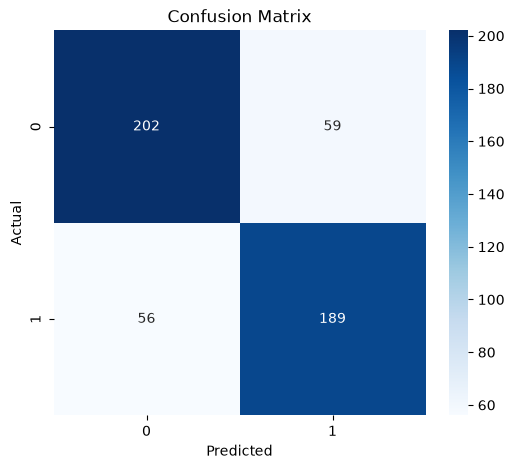

In [62]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [63]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.77      0.78       261
           1       0.76      0.77      0.77       245

    accuracy                           0.77       506
   macro avg       0.77      0.77      0.77       506
weighted avg       0.77      0.77      0.77       506



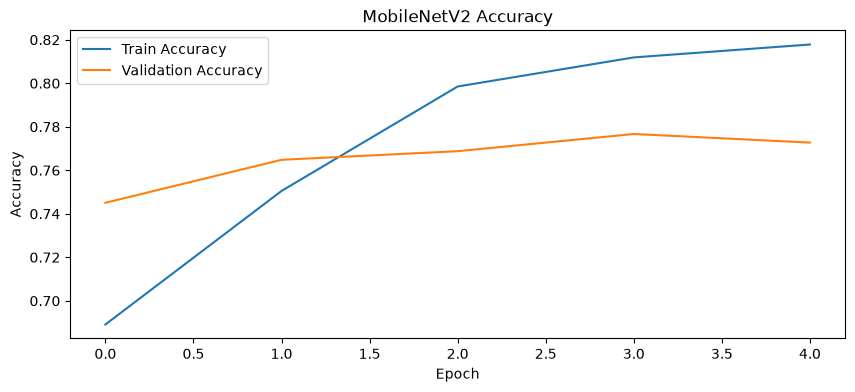

In [64]:
plt.figure(figsize=(10,4))

plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')

plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

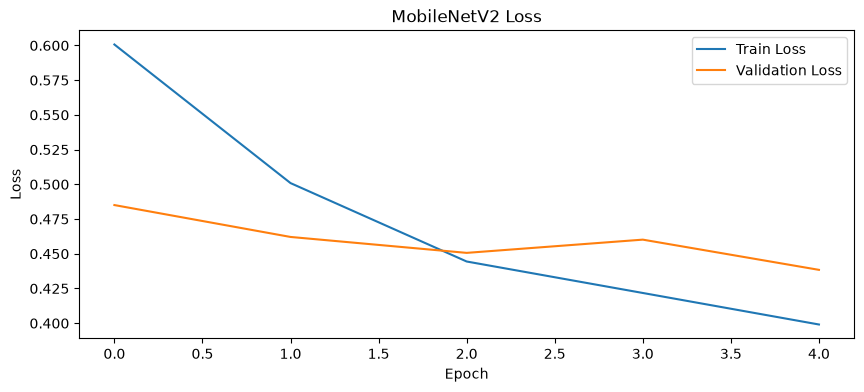

In [ ]:
plt.figure(figsize=(10,4))

plt.plot(history2.history['loss'], label='Train Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')

plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()=